# Day 9: Exploratory Data Analysis (EDA) Profiling Tools & Quality Audits
> **Programme:** C-DAC PGCP-AI (Data Analytics)  
> **Course:** Data Analytics  
> **Author:** abs6187 (`23f2000876@ds.study.iitm.ac.in`) | **Instructor Reference:** Mohamed Ali (`alilog`)  
> **Topic:** Automated Profiling Tools, Quality & Integrity Audits, Schema Validation, Dataset Overview Summaries

---

### The 4 Core Pillars of Data Profiling
1. **Comprehensive Automated Profiling:** Utilizing modern profiling tools (`Sweetviz`, `YData-Profiling`) to generate rich visual and statistical inspection dashboards.
2. **Automated Quality & Integrity Audits:** Auditing null rates, duplicate keys/records, out-of-bound anomalies, and calculating a unified Data Quality Health Score.
3. **Data Schema Validation:** Enforcing strict data contracts (types, ranges, nullability, categorical sets) before data reaches downstream pipelines.
4. **Dataset Overview Summaries:** High-level structural telemetry (`.shape`, `.dtypes`, deep memory usage, downcasting potential).

## Table of Contents
- [0. Global Setup & Imports](#0-global-setup--imports)
- [1. Comprehensive Profiling with Sweetviz & Automated Tools](#1-comprehensive-profiling-with-sweetviz--automated-tools)
- [2. Automated Quality and Integrity Audits](#2-automated-quality-and-integrity-audits)
- [3. Data Schema Validation (Defensive Data Contracts)](#3-data-schema-validation-defensive-data-contracts)
- [4. Dataset Overview Summaries & Memory Telemetry](#4-dataset-overview-summaries--memory-telemetry)
- [5. Summary Architecture Table & Viva Takeaways](#5-summary-architecture-table--viva-takeaways)

### 0. Global Setup & Imports
Initializing libraries for data wrangling, visualization, schema validation, and automated profiling.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Visual styling configuration
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for automated EDA and profiling loaded successfully.")

Global libraries for automated EDA and profiling loaded successfully.


---
### 1. Comprehensive Profiling with Sweetviz & Automated Tools
Automated profiling tools generate comprehensive univariate and bivariate reports in seconds.
Here, we analyze feature distributions both programmatically and via **Sweetviz**.

Descriptive Statistical Profile:


,Mean,Std Dev,Min,Median (50%),Max
age,43.55600,15.307257,18.00,44.000,69.00
income,60031.24072,15048.815340,21534.87,59806.020,108809.78
credit_score,574.12960,157.988371,301.40,582.400,848.50
purchase_amount,121.31368,109.118032,1.47,91.415,728.60


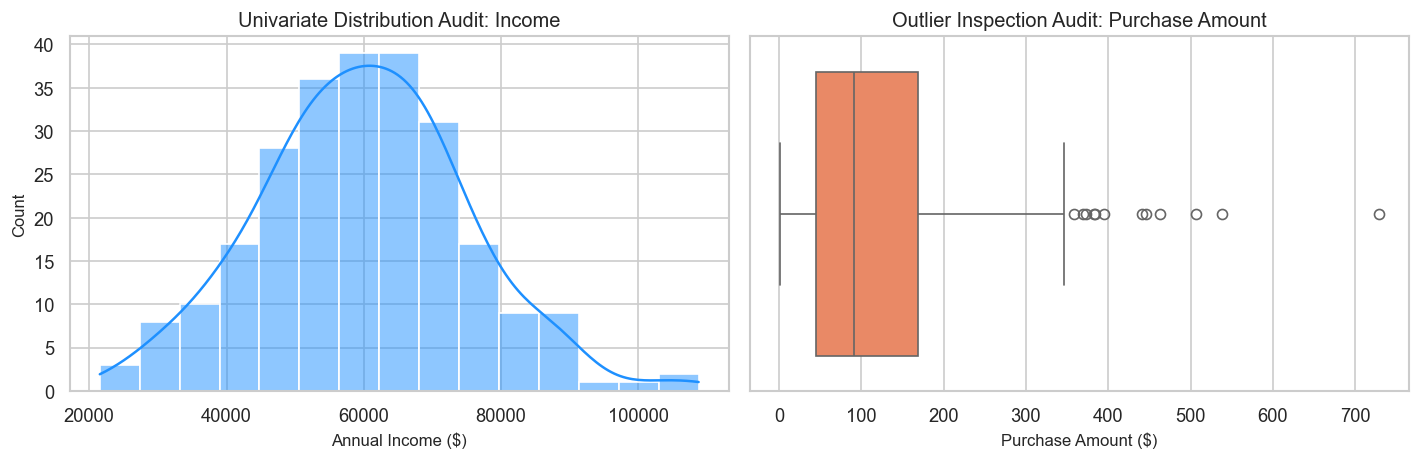

In [2]:
np.random.seed(42)
n_samples = 250

df_eda = pd.DataFrame({
    'age': np.random.randint(18, 70, n_samples),
    'income': np.random.normal(60000, 15000, n_samples).round(2),
    'credit_score': np.random.uniform(300, 850, n_samples).round(1),
    'purchase_amount': np.random.exponential(scale=120, size=n_samples).round(2)
})

profile_summary = df_eda.describe().T[['mean', 'std', 'min', '50%', 'max']]
profile_summary.columns = ['Mean', 'Std Dev', 'Min', 'Median (50%)', 'Max']
print("Descriptive Statistical Profile:")
display(profile_summary)

# Univariate Distribution Audit
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df_eda['income'], kde=True, color='dodgerblue', ax=axes[0])
axes[0].set_title('Univariate Distribution Audit: Income')
axes[0].set_xlabel('Annual Income ($)')

sns.boxplot(x=df_eda['purchase_amount'], color='coral', ax=axes[1])
axes[1].set_title('Outlier Inspection Audit: Purchase Amount')
axes[1].set_xlabel('Purchase Amount ($)')

plt.tight_layout()
plt.show()

In [3]:
import sweetviz as sv

# Generate an automated exploratory HTML report
report = sv.analyze(df_eda)
report_filename = "sweetviz_report.html"
report.show_html(filepath=report_filename, open_browser=False)

print(f"Sweetviz HTML Report successfully generated at: {os.path.abspath(report_filename)}")

                                             |          | [  0%]   00:00 -> (? left)

Report sweetviz_report.html was generated.
Sweetviz HTML Report successfully generated at: C:\Users\conne\Downloads\DATA_ANALYTICS_CDAC\sweetviz_report.html


---
### 2. Automated Quality and Integrity Audits
A critical role of EDA is detecting data defects before model planning:
1. **Missingness Audit:** Detecting missing values ($NaN$ / $Null$).
2. **Uniqueness Audit:** Detecting exact duplicate records and primary key collisions.
3. **Value Validity Audit:** Catching domain violations (e.g., negative prices, invalid statuses).

In [4]:
df_audit = pd.DataFrame({
    'id': [101, 102, 102, 104, 105, 106, 107],
    'customer_name': ['Alice', 'Bob', 'Bob', 'Charlie', 'David', 'Eva', 'Frank'],
    'status': ['Active', 'Pending', 'Pending', 'Closed', None, 'Active', 'UNKNOWN'],
    'amount': [150.0, 220.0, 220.0, -45.0, 510.0, 0.0, 890.0]
})

print("--- Raw Audit Dataset ---")
display(df_audit)

# 1. Null counts and ratios
null_counts = df_audit.isnull().sum()
null_ratio = (null_counts / len(df_audit)) * 100

# 2. Duplicate counts
duplicate_rows = df_audit.duplicated().sum()
pk_duplicates = df_audit['id'].duplicated().sum()

# 3. Anomaly checks (negative or zero amount)
amount_anomalies = (df_audit['amount'] <= 0).sum()

audit_results = pd.DataFrame({
    'Null Count': null_counts,
    'Missing (%)': null_ratio.round(2)
})

print("\n--- Column Completeness Audit ---")
display(audit_results)
print(f"Total Duplicate Rows: {duplicate_rows}")
print(f"Primary Key ('id') Collisions: {pk_duplicates}")
print(f"Business Rule Violations (amount <= 0): {amount_anomalies}")

--- Raw Audit Dataset ---


,id,customer_name,status,amount
0,101,Alice,Active,150.0
1,102,Bob,Pending,220.0
2,102,Bob,Pending,220.0
3,104,Charlie,Closed,-45.0
4,105,David,None,510.0
5,106,Eva,Active,0.0
6,107,Frank,UNKNOWN,890.0



--- Column Completeness Audit ---


,Null Count,Missing (%)
id,0,0.00
customer_name,0,0.00
status,1,14.29
amount,0,0.00


Total Duplicate Rows: 1
Primary Key ('id') Collisions: 1
Business Rule Violations (amount <= 0): 2


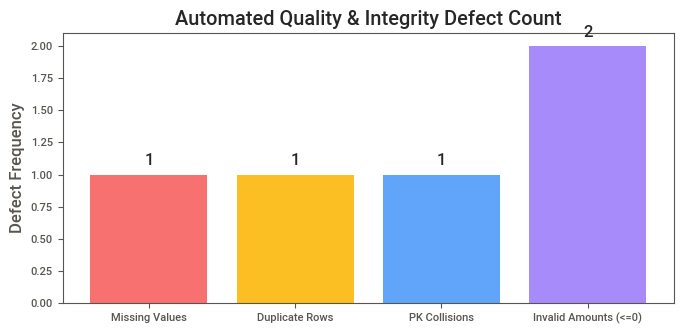

In [5]:
# Visualizing Data Quality Integrity Metrics
fig, ax = plt.subplots(figsize=(7, 3.5))

quality_metrics = {
    'Missing Values': int(null_counts.sum()),
    'Duplicate Rows': int(duplicate_rows),
    'PK Collisions': int(pk_duplicates),
    'Invalid Amounts (<=0)': int(amount_anomalies)
}

bars = ax.bar(quality_metrics.keys(), quality_metrics.values(), color=['#f87171', '#fbbf24', '#60a5fa', '#a78bfa'])
ax.set_title('Automated Quality & Integrity Defect Count')
ax.set_ylabel('Defect Frequency')

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2, yval + 0.05, f"{yval}", ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

---
### 3. Data Schema Validation (Defensive Data Contracts)
Schema validation defines declarative contracts to ensure incoming data conforms to required types, nullability rules, and value boundaries.

--- Schema Validation Compliance Audit ---


,Rule,Status,Details
0,User ID Uniqueness & Completeness,PASSED,All IDs unique
1,Age Range [0-120],FAILED,1 invalid age values
2,Status In Allowed Set,FAILED,1 illegal statuses
3,Non-Negative Spend,FAILED,1 negative spend values


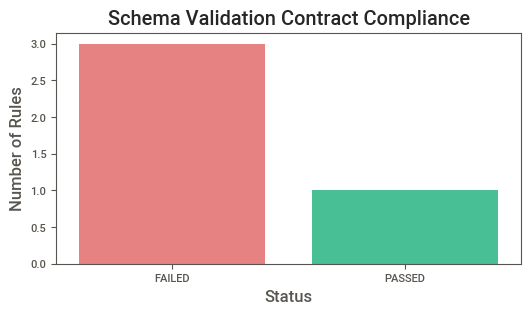

In [6]:
df_schema_test = pd.DataFrame({
    'user_id': [1, 2, 3, 4, 5],
    'age': [25, 42, -5, 19, 88],
    'status': ['Active', 'Pending', 'Active', 'Invalid_Status', 'Active'],
    'spend': [120.50, 450.00, 310.20, -15.00, 89.90]
})

def validate_dataframe(df):
    errors = []
    
    # Rule 1: user_id must be non-null and unique
    if df['user_id'].isnull().any():
        errors.append({'Rule': 'User ID Non-Null', 'Status': 'FAILED', 'Details': 'Found null user IDs'})
    elif not df['user_id'].is_unique:
        errors.append({'Rule': 'User ID Unique', 'Status': 'FAILED', 'Details': 'Duplicate user IDs found'})
    else:
        errors.append({'Rule': 'User ID Uniqueness & Completeness', 'Status': 'PASSED', 'Details': 'All IDs unique'})
        
    # Rule 2: age must be between 0 and 120
    invalid_age = df[(df['age'] < 0) | (df['age'] > 120)]
    if len(invalid_age) > 0:
        errors.append({'Rule': 'Age Range [0-120]', 'Status': 'FAILED', 'Details': f'{len(invalid_age)} invalid age values'})
    else:
        errors.append({'Rule': 'Age Range [0-120]', 'Status': 'PASSED', 'Details': 'All ages valid'})
        
    # Rule 3: status must be in allowed list
    allowed_status = {'Active', 'Pending', 'Closed'}
    invalid_status = df[~df['status'].isin(allowed_status)]
    if len(invalid_status) > 0:
        errors.append({'Rule': 'Status In Allowed Set', 'Status': 'FAILED', 'Details': f'{len(invalid_status)} illegal statuses'})
    else:
        errors.append({'Rule': 'Status In Allowed Set', 'Status': 'PASSED', 'Details': 'All statuses valid'})
        
    # Rule 4: spend must be strictly non-negative
    invalid_spend = df[df['spend'] < 0]
    if len(invalid_spend) > 0:
        errors.append({'Rule': 'Non-Negative Spend', 'Status': 'FAILED', 'Details': f'{len(invalid_spend)} negative spend values'})
    else:
        errors.append({'Rule': 'Non-Negative Spend', 'Status': 'PASSED', 'Details': 'All spend values valid'})
        
    return pd.DataFrame(errors)

validation_report = validate_dataframe(df_schema_test)
print("--- Schema Validation Compliance Audit ---")
display(validation_report)

# Plotting Compliance Status
status_counts = validation_report['Status'].value_counts()
plt.figure(figsize=(6, 3))
sns.barplot(x=status_counts.index, y=status_counts.values, hue=status_counts.index, palette={'PASSED': '#34d399', 'FAILED': '#f87171'}, legend=False)
plt.title('Schema Validation Contract Compliance')
plt.ylabel('Number of Rules')
plt.show()

---
### 4. Dataset Overview Summaries & Memory Telemetry
Fast structural profiling inspects shape, data types, cardinality, and memory footprint.

In [7]:
df_overview = pd.DataFrame({
    'order_id': [1001, 1002, 1003, 1004],
    'unit_price': [12.50, 45.00, 89.90, 5.25],
    'category': ['Stationery', 'Electronics', 'Electronics', 'Stationery'],
    'customer_rating': [4.5, 3.8, 4.9, 4.1]
})

print("1. Structural Dimensions:", df_overview.shape)
print("\n2. Data Type Breakdown:\n", df_overview.dtypes.value_counts())

# Detailed Overview Function
def dataset_telemetry(df):
    return pd.DataFrame({
        'Dtype': df.dtypes,
        'Non-Null Count': df.notnull().sum(),
        'Null Count': df.isnull().sum(),
        'Unique Count': df.nunique(),
        'Memory Footprint (bytes)': df.memory_usage(deep=True).drop('Index')
    })

print("\n3. Comprehensive Structural Telemetry:")
display(dataset_telemetry(df_overview))

1. Structural Dimensions: (4, 4)

2. Data Type Breakdown:
 float64    2
int64      1
object     1
Name: count, dtype: int64

3. Comprehensive Structural Telemetry:


,Dtype,Non-Null Count,Null Count,Unique Count,Memory Footprint (bytes)
order_id,int64,4,0,4,32
unit_price,float64,4,0,4,32
category,object,4,0,2,238
customer_rating,float64,4,0,4,32


---
## 5. Summary Architecture Table & Viva Takeaways

| Profiling & Audit Technique | Primary Tool / Method | Core Output / Metric | Primary Analytical Purpose |
| :--- | :--- | :--- | :--- |
| **Automated Profiling** | `Sweetviz` / `YData-Profiling` | Interactive HTML reports | Rapid visual and statistical inspection of feature interactions |
| **Quality & Integrity Audits** | `isnull()`, `duplicated()`, IQR | Null %, duplicate counts, domain outliers | Detecting structural defects and data corruption |
| **Schema Validation** | Declarative Data Contracts / Rules | Pass/Fail compliance per business rule | Enforcing data consistency before ingestion into ML pipelines |
| **Dataset Overview Summaries** | `df.info()`, `df.dtypes`, `memory_usage()` | Shape, cardinality, RAM footprint | Immediate sizing and structural sanity checking |

### Critical Viva / Interview Takeaways:
- **Difference between Profiling and Cleaning:** Profiling *diagnoses* and *surfaces* issues (auditing); cleaning *treats* and *resolves* them (imputation, dropping).
- **Why Automated Profiling isn't enough in production:** Tools like Sweetviz or YData-Profiling generate static HTML reports suitable for exploratory phases, but automated **schema validation rules** must be codified into production pipelines to assert data integrity programmatically.